# 04 · Grids: does it work on my grid?

Tutorial 01 traced a well on a regular DIS grid. Real models often use other grids: Voronoi or quadtree DISV grids refined around wells and rivers, DISU grids from older MODFLOW-USG workflows, and XT3D for anisotropic aquifers. This tutorial shows that `gwsource` treats them all the same way, and where they differ.

You will:

1. build the tutorial aquifer of tutorial 01 on four grids: DIS, a Voronoi DISV grid, and DISU with and without cell vertices;
2. trace the supply well with **exactly the same code** on each grid;
3. compare the capture zones side by side, and the well's water by source in a table;
4. see what a DISU grid without vertices can and cannot do;
5. add XT3D with rotated anisotropy, which makes the flow go round in **flow loops**, read the loop report and see why the answer is still exact;
6. build destination and source groups from **boundnames** and **zone arrays**;
7. export results to **GeoPackage** (for GIS) and **netCDF**.

**Runtime:** about 10 seconds (the last code cell prints the measured time). **Prerequisites:** tutorial 01; `bin/mf6` and `bin/triangle` (both downloaded by `scripts/setup_env.sh`).

## Settings

All settings live in this first cell. Model workspaces go to `tutorials/_work/04_grids/` (git-ignored, recreated on every run). The model builders and plotting helpers are in [`tutorials/herebedragons.py`](../herebedragons.py).

In [1]:
import contextlib
import io
import sys
import time
import warnings
from pathlib import Path

import flopy
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import LogNorm

sys.path.insert(0, str(Path.cwd().parent))  # tutorials/ holds the shared helpers
import herebedragons as hbd  # noqa: E402

import gwsource as gs  # noqa: E402

START = time.perf_counter()  # the notebook prints its run time at the end
WORK = hbd.work_dir("04_grids", clean=True)  # tutorials/_work/04_grids (git-ignored)
MF6 = hbd.mf6_exe()  # <repo>/bin/mf6
TRIANGLE = hbd.triangle_exe()  # <repo>/bin/triangle, used to build the Voronoi grid
WELL = "supply_well"  # boundname of the well we trace
THRESHOLDS = (0.1, 0.5)  # capture-zone contours of the fraction through
F_CAPTURE = 0.5  # capture zone: cells with F > F_CAPTURE
VORONOI_MAX_AREA = 2500.0  # m2, largest Triangle triangle: Voronoi cells about 50 m across
NOVERT = "DISU, no vertices"  # label of the DISU model built without cell geometry
ZOOM = (1150.0, 1750.0, 650.0, 1250.0)  # x0, x1, y0, y1 (m) of the close-up around the well
LAND_USE = {1: "farmland", 2: "village", 3: "woodland"}  # zone value: land use
LAND_USE_X = (700.0, 1300.0)  # m: land-use boundaries, west to east
SOURCE_LABELS = {"RCH": "recharge", "RIV": "river leakage", "CHD": "west edge (regional inflow)"}

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.0, 5.5)})
print(f"gwsource {gs.__version__}, FloPy {flopy.__version__}")

gwsource 0.0.1, FloPy 3.12.0.dev0


## 1. One aquifer, four grids

The physical problem is the one of tutorial 01: a 2 km × 2 km unconfined aquifer with recharge, a constant-head west edge, a river at x ≈ 1.5 km and a well pumping 800 m³/d, 100 m west of the river. The helper module builds it on four grids:

| Label | Grid | How it is built |
|---|---|---|
| DIS | 40 × 40 regular cells of 50 m | as in tutorial 01 |
| DISV | Voronoi cells of about 50 m | Triangle mesh of the domain, turned into Voronoi cells by FloPy; the river, the west edge and the well are placed on the cells by geometry (`hbd.build_voronoi`) |
| DISU | the DIS cells written as an unstructured grid, with cell vertices | `flopy.utils.gridutil.get_disu_kwargs` (`hbd.build_disu`) |
| DISU, no vertices | the same, without vertices | only cell areas, connections and connection geometry; no cell outlines |

The two DISU models have exactly the same cells and connections as the DIS model, so they solve the same equations. The Voronoi grid discretises the same aquifer differently.

In [2]:
runs = {
    "DIS": hbd.build_quickstart(WORK / "dis", MF6),
    "DISV": hbd.build_voronoi(WORK / "disv", MF6, TRIANGLE, max_area=VORONOI_MAX_AREA),
    "DISU": hbd.build_disu(WORK / "disu", MF6, with_vertices=True),
}
flopy_log = io.StringIO()
with contextlib.redirect_stdout(flopy_log):  # FloPy prints a warning each time it builds this grid
    runs[NOVERT] = hbd.build_disu(WORK / "disu_novert", MF6, with_vertices=False)
flopy_warnings = [line for line in flopy_log.getvalue().splitlines() if line.startswith("WARNING")]
print(f"FloPy printed {len(flopy_warnings)} warnings while writing the DISU model without vertices:")
for line in sorted(set(flopy_warnings)):
    print(f"  {flopy_warnings.count(line)} x {line}")
for label, run in runs.items():
    print(f"{label:18s} grid file {run.grb_file.name}")

FloPy printed 14 warnings while writing the DISU model without vertices:
  7 x WARNING: cell2d information missing. Functionality of the UnstructuredGrid will be limited.
  7 x WARNING: vertices information missing. Functionality of the UnstructuredGrid will be limited.
DIS                grid file quickstart.dis.grb
DISV               grid file voronoi.disv.grb
DISU               grid file disu.disu.grb
DISU, no vertices  grid file disu.disu.grb


While it writes the DISU model without vertices, FloPy prints a warning each time it builds the model grid. The warnings say that the grid has no cell outlines (`cell2d`) and no vertices. That is expected for this model. The cell above collects the warnings and prints how many there were. Section 5 shows what the missing outlines mean for tracing.

## 2. The same code on every grid

`gwsource` builds its flow graph from the binary grid file's connection arrays (IA and JA) and the FLOW-JA-FACE record of the budget file. MF6 writes both in the same form for DIS, DISV and DISU, so reading, selecting and tracing do not depend on the grid type. The loop below is the tutorial 01 trace, run unchanged on all four models:

In [3]:
steps, results = {}, {}
for label, run in runs.items():
    step = gs.read_step(run.ws, boundnames=True)
    well = gs.select(step, boundnames=[WELL])
    steps[label], results[label] = step, gs.backward(step, {WELL: well})

What differs between the grids is only the shape that per-cell results take when they are put back on the grid: `(nlay, nrow, ncol)` for DIS, `(nlay, ncpl)` for DISV and a flat list of nodes for DISU. The trace itself, its solver and the closure check (tutorial 01, §7) behave the same:

In [4]:
summary = {}
for label, step in steps.items():
    res = results[label]
    check = gs.diagnostics.backward_closure(step, res, WELL)
    summary[label] = {
        "grid type": step.grid_type,
        "result shape": step.grid_shape,
        "cells": step.n_cells,
        "solver": res.solver_used[0],
        "flow loops": len(res.cycles),
        "well inflow (m3/d)": round(res.destination_inflow[WELL], 3),
        "closure error": f"{check.relative_error:.1e}",
    }
display(pd.DataFrame(summary).T)

,grid type,result shape,cells,solver,flow loops,well inflow (m3/d),closure error
DIS,DIS,"(1, 40, 40)",1600,topological,0,800.0,0.0e+00
DISV,DISV,"(1, 1322)",1322,topological,0,800.0,0.0e+00
DISU,DISU,"(1600,)",1600,topological,0,800.0,0.0e+00
"DISU, no vertices",DISU,"(1600,)",1600,topological,0,800.0,0.0e+00


## 3. Capture zones side by side

First a close-up of the two different cell layouts around the well and the river. The Voronoi river is the chain of cells that the river line crosses, so it is not a straight column of cells as in DIS.

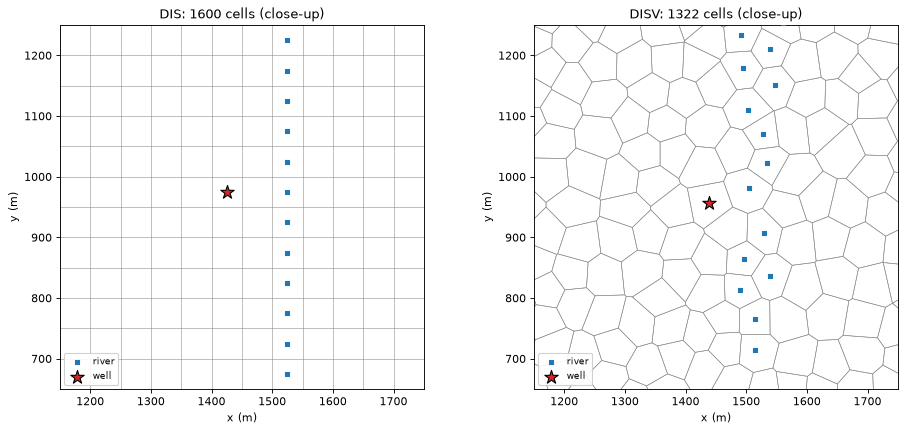

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.0, 5.5))
for ax, label in zip(axes, ("DIS", "DISV")):
    run = runs[label]
    pmv = flopy.plot.PlotMapView(modelgrid=hbd.model_grid(run.grb_file), ax=ax)
    pmv.plot_grid(linewidth=0.5, color="0.55")
    hbd.overlay_features(ax, run.grb_file, steps[label], packages=("RIV", "WEL"))
    ax.set_xlim(ZOOM[:2])
    ax.set_ylim(ZOOM[2:])
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(f"{label}: {steps[label].n_cells} cells (close-up)")
fig.tight_layout()
plt.show()

Now the fraction through $F$ on each grid, with the $F = 0.1$ (dashed) and $F = 0.5$ (solid) contours of tutorial 01. The grid file of the DISU model without vertices holds no cell outlines, so `gwsource` cannot draw it. Because we built that model ourselves, we know its node $n$ is DIS cell $n$, and draw its result on the DIS cells. With a real DISU model you would need the geometry from wherever the grid was made.

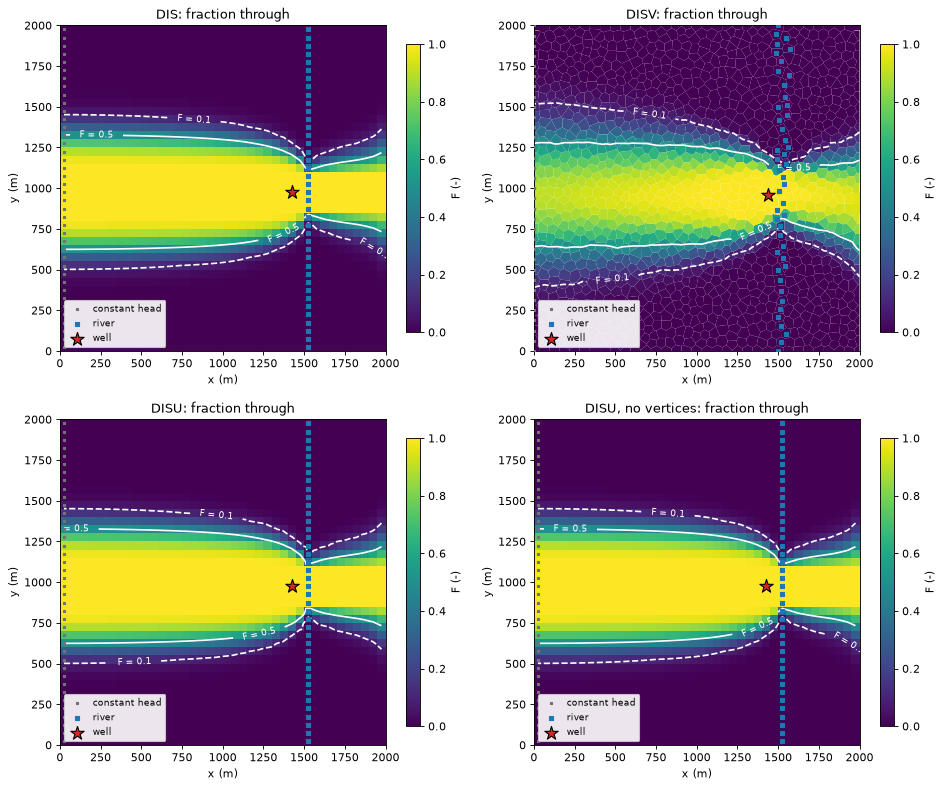

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12.0, 10.0))
for ax, label in zip(axes.flat, runs):
    geometry = "DIS" if label == NOVERT else label  # no outlines in the NOVERT grid file
    run, step = runs[geometry], steps[geometry]
    F = results[label].fraction_through[WELL]
    hbd.plot_cells(
        run.grb_file, step, F, ax=ax, cmap="viridis", vmin=0.0, vmax=1.0,
        title=f"{label}: fraction through", label="F (-)",
    )
    hbd.add_contours(ax, run.grb_file, step, F, THRESHOLDS, colors="w", linestyles=["--", "-"])
fig.tight_layout()
plt.show()

The two DISU maps are the DIS map, cell for cell. The Voronoi capture zone has the same shape and reach (back to the west edge, a tail across the river), with a slightly different outline. Its cells are differently shaped and oriented, and the notebook reads the different outline as full mixing smearing the zone edge a little differently on them. Numerical dispersion of full mixing is not smaller on Voronoi grids (see [`docs/dispersion_study.md`](../../docs/dispersion_study.md)).

## 4. The well's water by source on each grid

The table gives each source's share of the pumped water, two capture areas, and the largest difference in $F$ from the DIS result. The last column is only meaningful for the grids with the same cells. The two areas measure different things:

- the **expected area** $\sum_i F_i A_i$ counts each cell's area $A_i$ in proportion to the share $F_i$ of its water that reaches the well. It needs no threshold.
- the **area with $F > 0.5$** counts the whole area of every cell that sends more than half its water to the well, and nothing of the other cells.

The cell under the table prints how far each DISV value is from the DIS value, as a relative difference.

In [7]:
rows = {}
for label, res in results.items():
    table = hbd.volume_from_table(res, WELL)
    row = {SOURCE_LABELS[name]: share for name, share in table["share"].items()}
    F, area = res.fraction_through[WELL], steps[label].area
    row["expected area sum(F A) (km2)"] = float(F @ area) / 1e6
    row[f"area F > {F_CAPTURE} (km2)"] = area[F > F_CAPTURE].sum() / 1e6
    if steps[label].n_cells == steps["DIS"].n_cells:
        row["max |F - F_DIS|"] = np.abs(res.fraction_through[WELL] - results["DIS"].fraction_through[WELL]).max()
    rows[label] = row
shares = pd.DataFrame(rows).T
formats = {**{c: "{:.3f}" for c in shares.columns}, "max |F - F_DIS|": "{:.1e}"}
display(shares.apply(lambda col: col.map(lambda v: "–" if np.isnan(v) else formats[col.name].format(v))))
change = shares.loc["DISV"] / shares.loc["DIS"] - 1.0
print("DISV vs DIS:", ", ".join(f"{name} {change[name]:+.1%}" for name in shares.columns[:-1]))

,recharge,west edge (regional inflow),river leakage,expected area sum(F A) (km2),area F > 0.5 (km2),max |F - F_DIS|
DIS,0.711,0.148,0.142,1.173,1.143,0.0e+00
DISV,0.665,0.122,0.213,1.082,1.078,–
DISU,0.711,0.148,0.142,1.173,1.143,0.0e+00
"DISU, no vertices",0.711,0.148,0.142,1.173,1.143,0.0e+00


DISV vs DIS: recharge -6.4%, west edge (regional inflow) -17.5%, river leakage +50.3%, expected area sum(F A) (km2) -7.8%, area F > 0.5 (km2) -5.6%


- **DIS and DISU are identical** to machine precision: same cells, same connections, same flows, same answer, with or without vertices.
- **DISV is close but not equal.** The expected area is 7.8 % smaller and the area with $F > 0.5$ is 5.6 % smaller. The river supplies 21 % of the well's water instead of 14 %. The notebook reads this as a difference between the two *models* rather than in the tracing: the Voronoi grid puts the river and the well on different cells. The next cell prints the distances behind that reading.

In [8]:
for label in ("DIS", "DISV"):
    run, step, res = runs[label], steps[label], results[label]
    centres = gs.export.cell_centres(run.grb_file)
    well_xy = centres[np.flatnonzero(res.selections[WELL].cells)[0]]
    river = hbd.feature_cells(step, "RIV")
    gap = np.hypot(*(centres[river] - well_xy).T).min()
    riv = gs.select(step, package="RIV").terms
    leakage = step.term_flow[riv & (step.term_flow > 0)].sum()
    to_well = res.volume_from_by_term[WELL]["RIV"].sum()
    print(
        f"{label:4s}: well cell centre at x = {well_xy[0]:6.1f} m, nearest river cell centre "
        f"{gap:5.1f} m away; river leakage {leakage:5.1f} m3/d, of which {to_well:5.1f} reaches the well"
    )

DIS : well cell centre at x = 1425.0 m, nearest river cell centre 100.0 m away; river leakage 113.3 m3/d, of which 113.3 reaches the well
DISV: well cell centre at x = 1438.0 m, nearest river cell centre  70.0 m away; river leakage 170.3 m3/d, of which 170.3 reaches the well


In the DIS model the well's cell centre is two cells (100 m) from the river column. On the Voronoi grid the river is the chain of cells crossed by the river line. Some of their centres lie west of the line, and the nearest is only 70 m from the well's cell centre. The notebook attributes the larger river share on DISV to this shorter distance: a closer river would leak more water to the well, and that river water would replace part of the recharge in the well's budget. This is a reading of the printed numbers, not a test. The notebook does not change the distance alone to check it. In both models *all* the river leakage reaches the well, so every losing reach is inside the capture zone.

When you compare a capture zone between two grids, first check how each grid represents the boundaries near the destination. Here the boundary placement is the most visible difference between the two models.

## 5. DISU without vertices

An unstructured grid needs no cell outlines to be solved: MF6 needs only cell areas, the connections and the connection geometry. Many DISU models (for example, converted from MODFLOW-USG) are written that way. The binary grid file then holds no vertices, and `gwsource` has no geometry for that grid. What still works:

- **everything computed from the flow graph:** fractions, volumes, forward and backward modes, statistics, diagnostics (sections 2 and 4);
- **flux outputs** (volume per unit area), as long as the cell areas are known. The grid file holds no area for DISU, so `gs.read_step` reads the `AREA` array from the DISU input file with FloPy.

In [9]:
step_nv, res_nv = steps[NOVERT], results[NOVERT]
print("cell areas read from the DISU input (m2):", np.unique(step_nv.area))
print("flux outputs:", "available" if res_nv.flux_through is not None else "not available")

# With only the grid file and the budget file there is no area, so no flux outputs ...
files = gs.find_model_files(runs[NOVERT].ws)
bare = gs.read_step_files(files.grb_file, files.budget_file)
bare_res = gs.backward(bare, {WELL: gs.select(bare, package="WEL")})
print("grid + budget file only: area", bare.area, "| flux outputs", bare_res.flux_through)
# ... unless you pass the areas yourself
with_area = gs.read_step_files(files.grb_file, files.budget_file, area=np.full(bare.n_cells, 2500.0))
print("areas passed explicitly: flux outputs", gs.backward(with_area, {WELL: gs.select(with_area, package="WEL")}).flux_through is not None)

cell areas read from the DISU input (m2): [2500.]
flux outputs: available
grid + budget file only: area None | flux outputs None
areas passed explicitly: flux outputs True


What does **not** work is anything that needs cell outlines. `gwsource` stops with a message that says why:

In [10]:
try:
    gs.export.to_geopackage(WORK / "disu_novert.gpkg", step_nv, res_nv)
except AssertionError as err:
    print("GeoPackage export failed:", str(err).replace(str(WORK), "_work/04_grids"))  # short path

GeoPackage export failed: _work/04_grids/disu_novert/disu.disu.grb has no cell vertices: GeoPackage export of a DISU grid needs VERTICES and CELL2D in the DISU input (the binary grid file then carries them)


The full list:

| Feature | DIS | DISV | DISU with vertices | DISU without vertices |
|---|---|---|---|---|
| Fractions, volumes, forward/backward, statistics, diagnostics | yes | yes | yes | yes |
| Flux outputs, travel time (need cell area) | yes | yes | yes | yes, area from the DISU input (or passed with `area=`) |
| Maps (`gs.export.plot_map`, `hbd.plot_cells`) and GeoPackage | yes | yes | yes | no |
| netCDF and npz | `(layer, row, col)` | `(layer, icell2d)` | `(node)` | `(node)` |
| Particle comparison with MF6 PRT (tutorial 06) | yes | yes | no (PRT supports DIS and DISV only) | no |

DISU has no layers either: per-layer maps of a layered DISU model need a layer number per node from you.

## 6. XT3D: flow loops

With MF6's standard two-point flux, the flow between two connected cells is proportional to their head difference, so water always moves from the higher to the lower head. Going round a loop would mean going downhill all the way back to the start, which is impossible. The flow graph then has **no flow loops**, and the solver can use topological substitution (the `topological` solver in the table above).

**XT3D** computes the flow across a face from the heads of the surrounding cells as well. That is what makes it accurate for anisotropy that is not aligned with the grid, but it also means the flow across a face can run *against* the head difference of the two cells it joins. Flow loops then become possible. `hbd.build_xt3d` builds the tutorial aquifer with a heterogeneous log-normal $K$, 20:1 horizontal anisotropy and principal axes that rotate across the domain, solved with XT3D:

In [11]:
xt3d = hbd.build_xt3d(WORK / "xt3d", MF6)
step_x = gs.read_step(xt3d.ws, boundnames=True)
res_x = gs.backward(step_x, {WELL: gs.select(step_x, boundnames=[WELL])})
print(f"solver: {res_x.solver_used[0]}, flow loops: {len(res_x.cycles)}")
print(f"water entering the well: {res_x.destination_inflow[WELL]:.1f} m3/d")
display(hbd.volume_from_table(res_x, WELL).rename(index=SOURCE_LABELS).round(3))

solver: block, flow loops: 5
water entering the well: 800.0 m3/d


,volume_from,share
source,,
river leakage,509.25,0.637
recharge,290.75,0.363


The well's capture zone and sources are very different from the homogeneous model. Here most of the water comes from the river. The notebook attributes this to the heterogeneous, anisotropic $K$ field rather than to XT3D or the flow loops, which carry little water (see the loop report below). The left map shows $K$ along the major axis with the direction of that axis. The right map shows $F$ and outlines the cells of every flow loop.

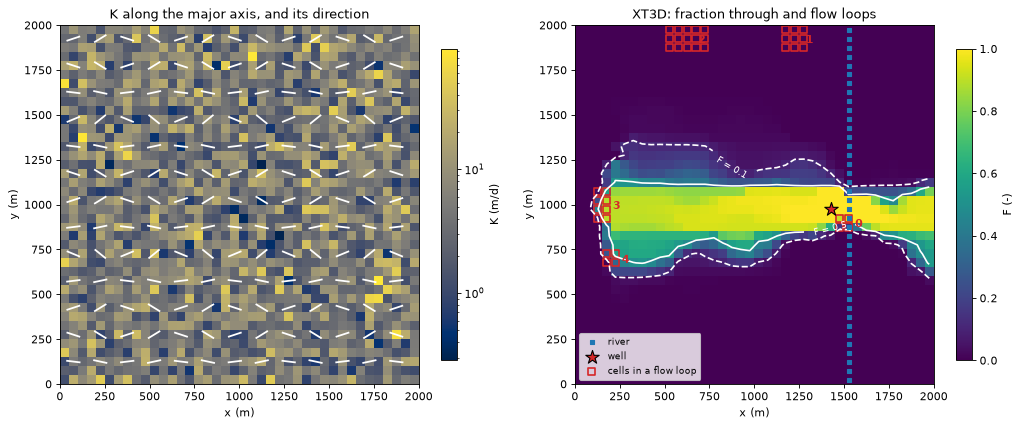

In [12]:
spec = xt3d.spec
cycles = gs.diagnostics.cycle_report(step_x, res_x)
cycle_id = gs.diagnostics.cycle_ids(step_x.n_cells, cycles)
centres = gs.export.cell_centres(xt3d.grb_file)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.2))
hbd.plot_cells(
    xt3d.grb_file, step_x, xt3d.info["k"].ravel(), ax=axes[0], cmap="cividis",
    norm=LogNorm(), title="K along the major axis, and its direction", label="K (m/d)", overlay=False,
)
angle = np.radians(xt3d.info["angle1"].ravel())
rows, cols = np.divmod(np.arange(step_x.n_cells), spec.ncol)
every = (rows % 3 == 1) & (cols % 3 == 1)  # one direction bar per 3 x 3 cells
axes[0].quiver(
    centres[every, 0], centres[every, 1], np.cos(angle[every]), np.sin(angle[every]),
    pivot="middle", headwidth=0, headlength=0, headaxislength=0, scale=25, color="w", width=0.005,
)
hbd.plot_cells(
    xt3d.grb_file, step_x, res_x.fraction_through[WELL], ax=axes[1], cmap="viridis", vmin=0.0,
    vmax=1.0, title="XT3D: fraction through and flow loops", label="F (-)", overlay=False,
)
hbd.add_contours(axes[1], xt3d.grb_file, step_x, res_x.fraction_through[WELL], THRESHOLDS, colors="w", linestyles=["--", "-"])
hbd.overlay_features(axes[1], xt3d.grb_file, step_x, packages=("RIV", "WEL"), legend=False)
in_cycle = cycle_id >= 0
axes[1].scatter(
    centres[in_cycle, 0], centres[in_cycle, 1], marker="s", s=40, facecolors="none",
    edgecolors="tab:red", linewidths=1.5, label="cells in a flow loop",
)
for i, c in enumerate(cycles):
    x, y = centres[c.cells].mean(axis=0)
    axes[1].annotate(str(i), (x, y), xytext=(10, -4), textcoords="offset points", color="tab:red", fontweight="bold")
axes[1].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

### The loop report

`gs.diagnostics.cycle_report` lists every **strongly connected set** of the flow graph: a group of cells in which water can get from any cell to any other, and so round and back again. Each such set holds one or more flow loops. Each row of the report gives

- `n_cells` and `internal_flow`: the size of the set and the sum of the flows on the connections inside it;
- `min_edge_flow`: the smallest of those flows (the one the reference method would delete, see below);
- `circulation`: how much water goes round. It is found by repeatedly taking out the smallest flow around a loop until no loop is left.
- `circulating_throughflow`: the same water counted cell by cell. Water that goes round a loop of five cells passes through each of the five. So 1 m³/d of circulation adds 5 m³/d to the summed throughflow of the cells. This column is circulation × loop length.
- `throughflow_share`: the circulating throughflow as a share of the model's total throughflow (the summed outflow of all cells).
- `closed`: whether the set has no exit at all. Water in a closed set can never reach any sink, so `gwsource` sets its fractions to 0 and reports it.

A second table says where each set is: the centre of its cells, the distance of that centre from the well cell, and the smallest and largest $F$ of its cells.

In [13]:
report = pd.DataFrame(gs.diagnostics.cycle_table(cycles)).set_index("cycle").rename_axis("set")
formats = {"internal_flow": "{:.2f}", "min_edge_flow": "{:.3f}", "circulation": "{:.3f}",
           "circulating_throughflow": "{:.2f}", "throughflow_share": "{:.1e}"}
display(report.drop(columns="cells").apply(lambda col: col.map(formats[col.name].format) if col.name in formats else col))

well_xy = centres[np.flatnonzero(res_x.selections[WELL].cells)[0]]
F_x = res_x.fraction_through[WELL]
where = pd.DataFrame({
    i: {"centre x (m)": centres[c.cells, 0].mean(), "centre y (m)": centres[c.cells, 1].mean(),
        "distance to well (m)": np.hypot(*(centres[c.cells].mean(axis=0) - well_xy)),
        "min F": F_x[c.cells].min(), "max F": F_x[c.cells].max()}
    for i, c in enumerate(cycles)
}).T.rename_axis("set")
display(where.round({"centre x (m)": 0, "centre y (m)": 0, "distance to well (m)": 0, "min F": 3, "max F": 3}))
total_throughflow = report["circulating_throughflow"].sum() / report["throughflow_share"].sum()  # m3/d
print(f"{in_cycle.sum()} of {step_x.n_cells} cells are in a flow loop.")
print(f"{report['circulation'].sum():.2f} m3/d circulates around the loops "
      f"({report['circulation'].sum() / total_throughflow:.1e} of the model throughflow).")
print(f"Counted cell by cell, the circulating throughflow is {report['circulating_throughflow'].sum():.1f} m3/d "
      f"({report['throughflow_share'].sum():.1e} of the model throughflow).")
csv_path = gs.export.save_cycle_report(WORK / "xt3d_cycles.csv", cycles)
print("loop report written to", csv_path.name)

,n_cells,internal_flow,min_edge_flow,circulation,circulating_throughflow,throughflow_share,closed
set,,,,,,,
0,4,43.17,2.475,2.475,9.90,3.6e-04,False
1,9,232.38,0.479,1.772,10.63,3.9e-04,False
2,15,117.14,0.120,0.120,1.20,4.3e-05,False
3,8,3.58,0.039,0.048,0.19,6.9e-06,False
4,4,0.93,0.006,0.006,0.02,8.2e-07,False


,centre x (m),centre y (m),distance to well (m),min F,max F
set,,,,,
0,1500.0,900.0,106.0,0.138,0.954
1,1225.0,1925.0,971.0,0.000,0.000
2,625.0,1925.0,1242.0,0.000,0.000
3,150.0,1000.0,1275.0,0.034,0.898
4,200.0,700.0,1255.0,0.001,0.564


40 of 1600 cells are in a flow loop.
4.42 m3/d circulates around the loops (1.6e-04 of the model throughflow).
Counted cell by cell, the circulating throughflow is 21.9 m3/d (8.0e-04 of the model throughflow).
loop report written to xt3d_cycles.csv


The sets are small (4 to 15 cells). Little water goes round in them. In total 4.4 m³/d circulates around the loops, 0.016 % of the model throughflow. Counted cell by cell, the circulating throughflow is 21.9 m³/d, 0.08 % of the model throughflow. Two measures of size give different rankings:

- **Circulation** is largest in set 0 (2.5 m³/d), about 100 m from the well.
- **Internal flow** is largest in set 1 (232 m³/d). Only 1.8 m³/d of that goes round. The rest passes through the set on its way to a sink.

Sets 3 and 4 lie near the west boundary, about 1.3 km from the well. Their cells span the edge of the capture zone, with $F$ from near 0 to 0.90 and 0.56. Sets 1 and 2 lie at the north edge (y ≈ 1.9 km), where $F = 0$. They are outside the capture zone. Large or strong flow loops would deserve a look at the model itself (solver convergence, extreme anisotropy).

### Which solver, and why the answer is still exact

Backward tracing solves the linear system $(\mathbf I - \mathbf P)\,\mathbf F = \mathbf S\,\mathbf D$ of tutorial 01. A flow loop does not change the equations. It only means the matrix cannot be reordered into triangular form, so substitution cell by cell is not possible. The default solver (`auto`) then switches to the **block** solver: it orders the strongly connected sets so that every set comes after the cells it drains to, and factorises the system in that order with a sparse LU. Each strongly connected set becomes a small block that is solved simultaneously. Every other cell is still solved by substitution. The result is the exact solution of the full-mixing equations, which three checks confirm:

In [14]:
groups_x = {WELL: gs.select(step_x, boundnames=[WELL])}
lu = gs.backward(step_x, groups_x, gs.TraceConfig(solver="lu"))
print(f"block vs plain sparse LU of the whole matrix: max |dF| = "
      f"{np.abs(lu.fraction_through[WELL] - res_x.fraction_through[WELL]).max():.1e}")
check = gs.diagnostics.backward_closure(step_x, res_x, WELL)
print(f"closure: sum of volume from {check.lhs:.4f} m3/d vs pumping {check.rhs:.4f} m3/d "
      f"(relative error {check.relative_error:.1e})")
try:
    gs.backward(step_x, groups_x, gs.TraceConfig(solver="topological"))
except AssertionError as err:
    print("topological solver:", err)

block vs plain sparse LU of the whole matrix: max |dF| = 3.3e-16
closure: sum of volume from 800.0000 m3/d vs pumping 800.0000 m3/d (relative error 1.4e-16)
topological solver: the flow graph has cycles; the topological solver cannot be used (use 'auto' or 'block')


The reference method (Foley and Black 2013) handles flow loops differently. It deletes the smallest connection of each loop until the graph has none, then uses topological substitution. That changes the flow field (the cells next to a deleted connection no longer balance) and so the answer. `gwsource` keeps that behaviour only in **net mode** (`accounting="net"`, `remove_cycles=True`), for comparison with studies made with the reference method. On this model the difference from the exact net-mode solution is:

In [15]:
net_exact = gs.backward(step_x, groups_x, gs.TraceConfig(accounting="net"))
net_deleted = gs.backward(step_x, groups_x, gs.TraceConfig(accounting="net", remove_cycles=True))
delta = np.abs(net_deleted.fraction_through[WELL] - net_exact.fraction_through[WELL])
print(f"net mode, solver {net_exact.solver_used[0]} vs edges deleted ({net_deleted.solver_used[0]}): "
      f"max |dF| = {delta.max():.3f}, in {np.sum(delta > 0.01)} cells above 0.01")

net mode, solver block vs edges deleted (topological): max |dF| = 0.155, in 24 cells above 0.01


Deleting a few m³/d of flow shifts $F$ by up to about 0.15, and by more than 0.01 in about two dozen cells around the flow loops that touch the capture zone. It is a local error. It is also avoidable, and with strong flow loops it would grow. Gross accounting (the default) has no edge deletion at all. Tutorial 02 covers gross vs net accounting.

## 7. Groups from boundnames and zone arrays

So far the destination was one well, picked by its boundname. Two selectors build groups from model features in bulk, and both work on any grid. We use the Voronoi model here.

### Boundnames: one group per river reach

The river is split into reaches named `river_north` and `river_south`. `gs.groups_by_boundname(step, package="RIV")` makes one group per boundname of the river package. Traced together with the well, the three groups answer "which outlet does the water of each cell leave through?"

supply_well :   1 terms, takes   800.0 m3/d
river_north :  25 terms, takes   874.3 m3/d
river_south :  21 terms, takes   769.0 m3/d


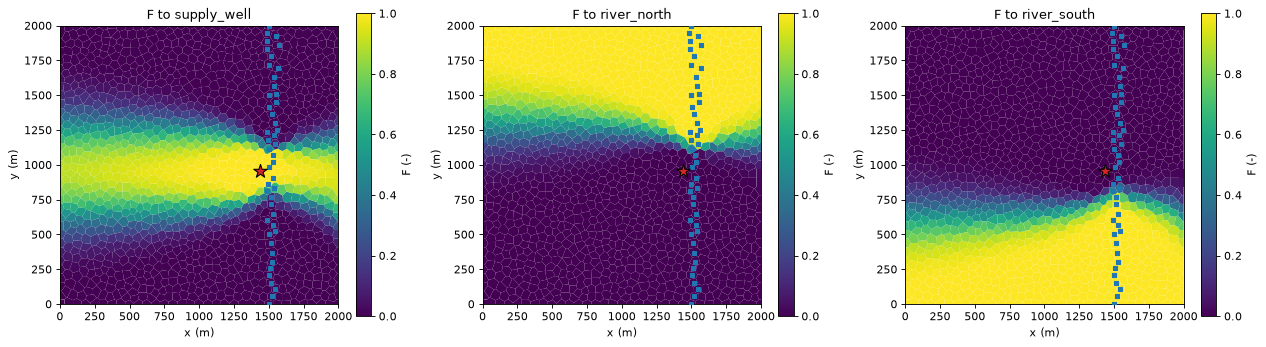

In [16]:
step_v = steps["DISV"]
rivers = gs.groups_by_boundname(step_v, package="RIV")
outlets = {WELL: gs.select(step_v, boundnames=[WELL]), **rivers}
res_v = gs.backward(step_v, outlets)
for name in outlets:
    print(f"{name:12s}: {outlets[name].terms.sum():3d} terms, takes {res_v.destination_inflow[name]:7.1f} m3/d")

run_v = runs["DISV"]
fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.8))
for ax, name in zip(axes, outlets):
    hbd.plot_cells(
        run_v.grb_file, step_v, res_v.fraction_through[name], ax=ax, cmap="viridis", vmin=0.0,
        vmax=1.0, title=f"F to {name}", label="F (-)", overlay=False,
    )
    hbd.overlay_features(ax, run_v.grb_file, step_v, packages=("RIV", "WEL"), legend=False)
fig.tight_layout()
plt.show()

The well and the two river reaches are the only sinks in the model (the constant-head edge only supplies water), so every drop leaves through one of the three. Their fractions therefore add up to 1 in every cell: a **boundary-control map** (tutorial 02). The north and south reaches split the aquifer east–west along the middle row, except where the well's capture zone cuts in.

In [17]:
total = sum(res_v.fraction_through[name] for name in outlets)
print(f"sum of F over the three outlets: min {total.min():.12f}, max {total.max():.12f}")

sum of F over the three outlets: min 1.000000000000, max 1.000000000000


### Zone arrays: how much of the well's water fell on each land use?

A zone array gives every cell an integer. Here the land is divided into three bands, farmland in the west, a village in the centre and woodland in the east, from the x coordinate of each cell centre. The same line of code works for any grid because it only needs the cell centres.

`gs.groups_by_zone(step, zones, package="RCH")` makes one group per zone value, holding the recharge terms of the cells in that zone. Traced **forward** (tutorial 03), each group's `volume_to_by_term[...]["WEL"]` is the recharge from that zone that ends in the well. (`gs.select_zone(step, zones, 2, package="RCH")` gives a single zone's group.)

In [18]:
land_rows = {}
for label in ("DIS", "DISV"):
    step, run = steps[label], runs[label]
    zones = np.digitize(gs.export.cell_centres(run.grb_file)[:, 0], LAND_USE_X) + 1  # 1, 2, 3
    groups = gs.groups_by_zone(step, zones, package="RCH")
    fwd = gs.forward(step, groups)
    well_cell = np.flatnonzero(results[label].selections[WELL].cells)[0]
    row = {LAND_USE[int(g.removeprefix("zone_"))]: fwd.volume_to_by_term[g]["WEL"][well_cell] for g in groups}
    row["all recharge (backward)"] = results[label].volume_from_by_term[WELL]["RCH"].sum()
    land_rows[label] = row
land = pd.DataFrame(land_rows).T
land.loc["DISV vs DIS (%)"] = 100.0 * (land.loc["DISV"] / land.loc["DIS"] - 1.0)
display(land.round(1).rename_axis("m3/d reaching the well"))

,farmland,village,woodland,all recharge (backward)
m3/d reaching the well,,,,
DIS,228.7,193.5,146.4,568.6
DISV,214.3,173.2,144.7,532.2
DISV vs DIS (%),-6.3,-10.5,-1.2,-6.4


The capture zone is a band of nearly constant width from the west edge to the river (map below). Each land use therefore contributes roughly in proportion to the length of the band it covers. The farmland (700 m) contributes most, then the village (600 m). The woodland share comes from the short stretch west of the river and from the tail across it. The rest of the 800 m³/d is regional inflow from the west edge and river water. The forward split by zone adds up to the recharge share found by the *backward* trace (last column): the forward/backward duality of tutorial 03. On DISV each zone sends 1.2 to 10.5 % less recharge to the well than on DIS (last row). In total the DISV well receives 6.4 % less recharge, the same relative difference as the recharge share in section 4.

For the backward direction a zone array selects destinations in the same way: `gs.select_zone(step, zones, 3, package="RIV")` would be the river cells in the woodland band. The zone map with the well's $F = 0.5$ contour on the Voronoi grid:

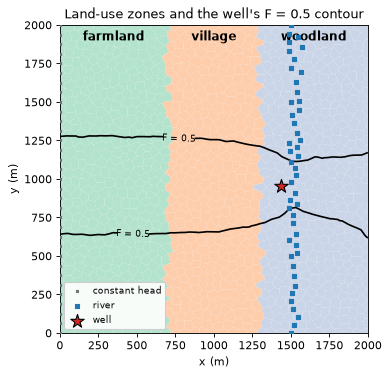

In [19]:
zones_v = np.digitize(gs.export.cell_centres(run_v.grb_file)[:, 0], LAND_USE_X) + 1
ax = hbd.plot_cells(
    run_v.grb_file, step_v, zones_v.astype(float), cmap="Pastel2", vmin=0.5, vmax=8.5,
    title="Land-use zones and the well's F = 0.5 contour", colorbar=False,
)
hbd.add_contours(ax, run_v.grb_file, step_v, res_v.fraction_through[WELL], (0.5,), colors="k")
for value, name in LAND_USE.items():
    x = np.mean(np.r_[0.0, LAND_USE_X, 2000.0][value - 1 : value + 1])
    ax.text(x, 1900.0, name, ha="center", fontsize=11, fontweight="bold")
plt.show()

## 8. Export to GeoPackage and netCDF

**GeoPackage** is the format for GIS. `gs.export.to_geopackage` writes one polygon per cell (from the grid file's vertices) and one column per output and group, named `<output>__<group>`, plus one column per source package of the split (`volume_from_by_term__<group>__<package>`). DIS and DISV grids get one layer per model layer (`layer_1`, ...). DISU gets one layer `nodes`. The tutorial model has local coordinates and no coordinate reference system (CRS), so the cell below silences geopandas' warning about it. For a real model, pass its coordinate reference system with `crs=` (e.g. `crs="EPSG:2193"`) so the layers land in the right place.

Open the file in **QGIS** with *Layer → Add Layer → Add Vector Layer* (or drag it into the map), and style a column with a graduated renderer, e.g. `fraction_through__supply_well` with breaks at 0.1 and 0.5. Here we read it back with geopandas:

voronoi_outlets.gpkg: 1322 polygons, 33 columns


,layer,icell2d,active,fraction_through__supply_well,fraction_through__river_north,volume_from__supply_well,geometry
0,1,1,1,0.0007,0.0000,0.0032,"POLYGON ((0 31.25, 32 31.25, 32 0, 0 0, 0 31.25))"
1,1,2,1,0.0000,0.0000,0.0000,"POLYGON ((1968.75 14.377, 1985.623 31.25, 2000..."
2,1,3,1,0.0000,1.0000,0.0000,"POLYGON ((1968.75 2000, 2000 2000, 2000 1968.7..."
3,1,4,1,0.0001,0.9999,0.0007,"POLYGON ((0 2000, 31.25 2000, 31.25 1968.75, 0..."
4,1,5,1,0.9888,0.0107,1.6857,"POLYGON ((984.067 1038.467, 1027.806 1020.304,..."


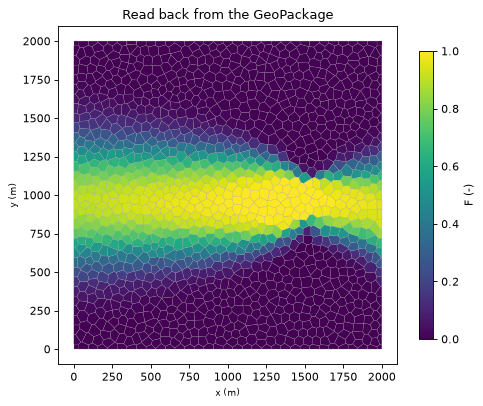

In [20]:
with warnings.catch_warnings():  # the tutorial model has local coordinates and no CRS
    warnings.filterwarnings("ignore", message="'crs' was not provided")
    gpkg_path = gs.export.to_geopackage(WORK / "voronoi_outlets.gpkg", step_v, res_v)
frame = gpd.read_file(gpkg_path, layer="layer_1")
print(f"{gpkg_path.name}: {len(frame)} polygons, {frame.shape[1] - 1} columns")
columns = ["layer", "icell2d", "active", f"fraction_through__{WELL}", "fraction_through__river_north", f"volume_from__{WELL}"]
display(frame[columns + ["geometry"]].head().round(4))

ax = frame.plot(
    column=f"fraction_through__{WELL}", cmap="viridis", vmin=0.0, vmax=1.0, edgecolor="0.6",
    linewidth=0.2, legend=True, legend_kwds={"label": "F (-)", "shrink": 0.85}, figsize=(7.0, 5.5),
)
ax.set_title("Read back from the GeoPackage")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
plt.show()

**netCDF** keeps the result as labelled arrays with units and a provenance record, for xarray, Panoply or further processing. The grid dimensions follow the grid type, so the same variable has different dimensions on each grid:

In [21]:
for label, filename in (("DIS", "dis.nc"), ("DISV", "disv.nc"), (NOVERT, "disu_novert.nc")):
    nc_path = gs.export.to_netcdf(WORK / filename, steps[label], results[label])
    with xr.open_dataset(nc_path) as ds:
        f_nc = ds["fraction_through"].sel(group=WELL)
        print(f"{label:18s} {filename:15s} fraction_through dims {dict(f_nc.sizes)}")
        assert np.allclose(f_nc.values.ravel(), results[label].fraction_through[WELL], equal_nan=True)

with xr.open_dataset(WORK / "disv.nc") as ds:
    shares_nc = ds["volume_from_by_term"].sel(group=WELL).sum("icell2d").squeeze()
    display(shares_nc.to_pandas().rename("volume from (m3/d)").round(1).to_frame())

DIS                dis.nc          fraction_through dims {'layer': 1, 'row': 40, 'col': 40}
DISV               disv.nc         fraction_through dims {'layer': 1, 'icell2d': 1322}
DISU, no vertices  disu_novert.nc  fraction_through dims {'node': 1600}


,volume from (m3/d)
package,
CHD,97.5
RCH,532.2
RIV,170.3


The DISU file without vertices still holds every output, indexed by node: it is the format to use when there is no geometry to map.

## 9. Sanity checks

The claims of this tutorial, as assertions: DIS and DISU agree to machine precision, every trace closes, the outlet fractions sum to 1, and the block solver matches the plain LU on the XT3D model.

In [22]:
for label in ("DISU", NOVERT):
    assert np.allclose(results[label].fraction_through[WELL], results["DIS"].fraction_through[WELL], rtol=0.0, atol=1e-12)
for label, step in {**steps, "XT3D": step_x}.items():
    res = results.get(label, res_x)
    assert gs.diagnostics.backward_closure(step, res, WELL).relative_error < 1e-8, label
assert np.allclose(total, 1.0, atol=1e-10)
assert np.allclose(lu.fraction_through[WELL], res_x.fraction_through[WELL], atol=1e-12)
assert res_x.solver_used == ["block"] and len(cycles) > 0
print("all checks passed")
print(f"notebook run time: {time.perf_counter() - START:.0f} s")

all checks passed
notebook run time: 4 s


## Key points

- The method needs only the cell connections and the flows across them, which MF6 writes the same way for **DIS, DISV and DISU**: the code to read, select and trace is identical on every grid.
- The same cells and connections give the same answer: **DIS and DISU agree to machine precision**. A **Voronoi** model of the same aquifer is close but not equal. The notebook attributes most of the difference to where the Voronoi grid puts the river. Check boundary placement first when comparing grids.
- A **DISU grid without vertices** supports every result computed from the flow graph, and flux outputs with the areas read from the DISU input. Maps and GeoPackage need cell outlines. MF6 PRT needs DIS or DISV.
- **XT3D** can make the flow go round in flow loops. The default solver then switches from topological substitution to a block-triangular sparse LU, and the answer stays exact. The **loop report** (`cycle_report`) shows where the loops are and how much water goes round. Deleting loop connections, as the reference method does, is only available in net mode, for comparison.
- **Boundnames** and **zone arrays** build groups in bulk (`groups_by_boundname`, `groups_by_zone`, `select_zone`) on any grid.
- **GeoPackage** export gives polygon layers for QGIS. **netCDF** gives labelled arrays for xarray, with dimensions that follow the grid type.

## Next

[05 · Transient snapshots](../05_transient_snapshots/05_transient_snapshots.ipynb): how the capture zone changes through the seasons, statistics over time steps, and storage as a source.